# Генерация реалистичных изображений лиц с помощью вариационного автокодировщика (VAE) на датасете CelebA

**Автор:** Трофимчук Дмитрий  
**Дата:** 2026-07-09

**Аннотация:**  
В данной работе реализован вариационный автокодировщик (VAE) для генерации изображений лиц знаменитостей (датасет CelebA). Модель обучается сжимать изображения размером 64×64 в латентное пространство размерности 128 и восстанавливать их. После обучения демонстрируется реконструкция, генерация новых лиц и интерполяция между ними. Проведён анализ качества с помощью метрик PSNR и SSIM, визуализировано латентное пространство с использованием t-SNE. Проект выполнен в рамках практической работы по курсу «Глубокое обучение».

In [ ]:
# Установка необходимых библиотек
!pip install -q torch torchvision matplotlib seaborn scikit-learn plotly tqdm gdown

# Импорты
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from tqdm import tqdm
import os
import time
from sklearn.manifold import TSNE
from sklearn.metrics import mean_squared_error
from IPython.display import display, HTML
import plotly.express as px
import plotly.graph_objects as go
from torchvision.utils import make_grid
import warnings
warnings.filterwarnings('ignore')
import ipywidgets as widgets
from ipywidgets import interact

# Определение устройства
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Устройство:", device)

Устройство: cuda


B## Теоретическое обоснование

### Проблема генерации изображений
Создание реалистичных синтетических изображений – одна из ключевых задач компьютерного зрения. Вариационные автокодировщики (VAE) позволяют не только реконструировать входные данные, но и генерировать новые образцы, обучаясь на распределении данных. В данном проекте мы применяем VAE для генерации лиц знаменитостей.

### Основные концепции
- **Автокодировщик** – нейросеть, состоящая из кодера (сжатие) и декодера (восстановление).
- **VAE** – вероятностная модель, где кодер выдаёт параметры распределения (μ, log σ²) в латентном пространстве, а декодер генерирует данные из сэмплов этого распределения.
- **Перепараметризация** – трюк, позволяющий дифференцировать семплирование и обучать модель с помощью градиентного спуска.

### Математическое обоснование
Нижняя граница вариационной оценки (ELBO):

Вариационная нижняя граница (Evidence Lower Bound) для VAE записывается как:

$$
\mathcal{L}(\theta, \phi; x) =
\mathbb{E}_{z \sim q_\phi(z|x)} \big[ \log p_\theta(x|z) \big]
- D_{KL}\big( q_\phi(z|x) \,\|\, p(z) \big)
$$

где:
- $q_\phi(z|x)$ – апостериорное распределение в латентном пространстве (кодер),
- $p_\theta(x|z)$ – правдоподобие данных при заданном $z$ (декодер),
- $p(z)$ – априорное распределение латентного вектора (обычно $\mathcal{N}(0, I)$),
- $\mathbb{E}_{z \sim q}$ – математическое ожидание по выборкам из $q$,
- $D_{KL}$ – дивергенция Кульбака–Лейблера, измеряющая "расстояние" между двумя распределениями.

Первое слагаемое отвечает за **точность реконструкции** (MSE или BCE), второе – за **регуляризацию**, штрафуя отклонение от нормального распределения.

### Схема архитектуры
Изображение (3×64×64)

↓

 Encoder (4 свёрточных слоя с ReLU)  


↓

μ, log σ² (размерность 128)

↓

Семплирование (reparameterization)

↓

z (размерность 128)

↓


 Decoder (4 транспонированных свёрточных слоя + Tanh)

↓

Реконструкция (3×64×64)

## Подготовка данных

### Датасет CelebA
Используется датасет CelebA (CelebFaces Attributes), содержащий более 200 000 изображений лиц знаменитостей с атрибутами. В работе используются только изображения (без атрибутов). Датасет автоматически загружается с помощью `torchvision.datasets.CelebA`.

### Предобработка
- Все изображения приводятся к размеру 64×64.
- Применяется центрирование и нормализация в диапазон [-1, 1] (для устойчивости обучения с Tanh на выходе декодера).

### Разделение на выборки
Датасет уже размечен на train (162 770), validation (19 867) и test (19 962) изображений. Используются соответствующие разделы.

Загрузка датасета CelebA...


Downloading...
From (original): https://drive.google.com/uc?id=0B7EVK8r0v71pZjFTYXZWM3FlRnM
From (redirected): https://drive.usercontent.google.com/download?id=0B7EVK8r0v71pZjFTYXZWM3FlRnM&confirm=t&uuid=8b7f0830-ed69-4e0f-9a2a-f7d4a381f956
To: /content/data/celeba/img_align_celeba.zip
100%|██████████| 1.44G/1.44G [00:17<00:00, 80.9MB/s]
Downloading...
From: https://drive.google.com/uc?id=0B7EVK8r0v71pblRyaVFSWGxPY0U
To: /content/data/celeba/list_attr_celeba.txt
100%|██████████| 26.7M/26.7M [00:00<00:00, 73.5MB/s]
Downloading...
From: https://drive.google.com/uc?id=1_ee_0u7vcNLOfNLegJRHmolfH5ICW-XS
To: /content/data/celeba/identity_CelebA.txt
100%|██████████| 3.42M/3.42M [00:00<00:00, 219MB/s]
Downloading...
From: https://drive.google.com/uc?id=0B7EVK8r0v71pbThiMVRxWXZ4dU0
To: /content/data/celeba/list_bbox_celeba.txt
100%|██████████| 6.08M/6.08M [00:00<00:00, 37.0MB/s]
Downloading...
From: https://drive.google.com/uc?id=0B7EVK8r0v71pd0FJY3Blby1HUTQ
To: /content/data/celeba/list_landma

Train: 162770, Val: 19867, Test: 19962


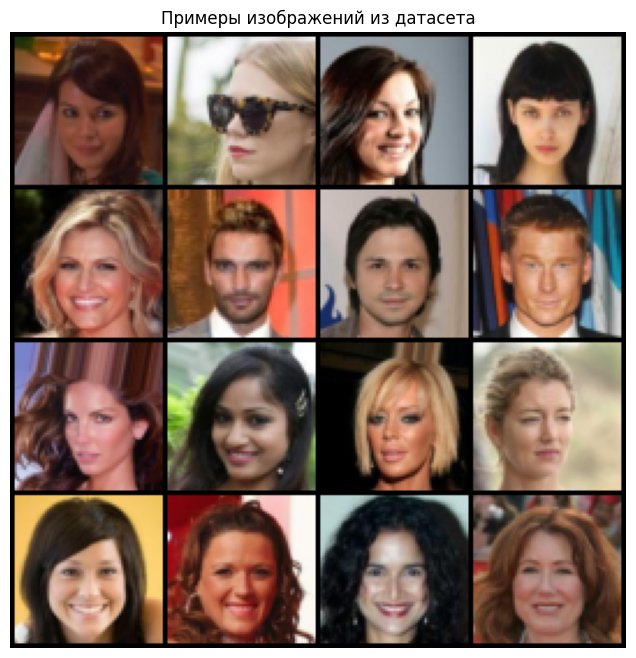

In [ ]:
# Параметры
IMAGE_SIZE = 64
BATCH_SIZE = 128
LATENT_DIM = 128
EPOCHS = 5          # для ускорения (можно увеличить до 10, но тогда обучение дольше)
LR = 1e-3

# Трансформации
transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

# Загрузка датасета
print("Загрузка датасета CelebA...")
train_dataset = datasets.CelebA(root='./data', split='train', download=True, transform=transform)
val_dataset = datasets.CelebA(root='./data', split='valid', download=True, transform=transform)
test_dataset = datasets.CelebA(root='./data', split='test', download=True, transform=transform)

# Опционально: используйте подвыборку для ускорения (раскомментируйте при необходимости)
# train_dataset = Subset(train_dataset, range(5000))
# val_dataset = Subset(val_dataset, range(1000))
# test_dataset = Subset(test_dataset, range(1000))

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"Train: {len(train_dataset)}, Val: {len(val_dataset)}, Test: {len(test_dataset)}")

# Визуализация примеров
def show_images(dataloader, n=16):
    dataiter = iter(dataloader)
    images, _ = next(dataiter)
    images = images[:n]
    grid = make_grid(images, nrow=4, normalize=True, value_range=(-1,1))
    plt.figure(figsize=(8,8))
    plt.imshow(grid.permute(1,2,0).cpu().numpy())
    plt.axis('off')
    plt.title("Примеры изображений из датасета")
    plt.show()

show_images(train_loader)

## Реализация модели VAE

### Архитектура
- **Encoder**: 4 свёрточных слоя с числом каналов 32→64→128→256, ядром 4, шагом 2, padding=1. После каждого слоя – ReLU. Выход – 256×4×4, затем полносвязные слои для μ и log σ² размерности 128.
- **Decoder**: полносвязный слой 128→256×4×4, затем 4 транспонированных свёрточных слоя с каналами 256→128→64→32→3, ядром 4, шагом 2, padding=1. После первых трёх – ReLU, на выходе – Tanh.

### Гиперпараметры
- Размерность латентного пространства: 128
- Размер батча: 128
- Скорость обучения: 1e-3 (Adam)
- Количество эпох: 5 (можно увеличить до 10)

### Функция потерь
- Ошибка реконструкции: MSE (сумма по пикселям)
- KL-дивергенция: −0.5 * Σ(1 + log σ² − μ² − σ²)
- Итог: L = recon_loss + kl_loss

In [ ]:
class VAE(nn.Module):
    def __init__(self, latent_dim=128):
        super(VAE, self).__init__()
        self.latent_dim = latent_dim

        # Encoder
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(128, 256, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),
        )
        self.fc_mu = nn.Linear(256 * 4 * 4, latent_dim)
        self.fc_logvar = nn.Linear(256 * 4 * 4, latent_dim)

        # Decoder
        self.decoder_fc = nn.Linear(latent_dim, 256 * 4 * 4)
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(32, 3, kernel_size=4, stride=2, padding=1),
            nn.Tanh()
        )

    def encode(self, x):
        h = self.encoder(x)
        h = h.view(h.size(0), -1)
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        return mu, logvar

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        h = self.decoder_fc(z)
        h = h.view(h.size(0), 256, 4, 4)
        return self.decoder(h)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        recon = self.decode(z)
        return recon, mu, logvar

model = VAE(LATENT_DIM).to(device)
print(f"Модель создана. Параметров: {sum(p.numel() for p in model.parameters()):,}")

Модель создана. Параметров: 2,957,251


In [ ]:
def loss_function(recon, x, mu, logvar):
    recon_loss = F.mse_loss(recon, x, reduction='sum')
    kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return recon_loss + kl_loss

optimizer = optim.Adam(model.parameters(), lr=LR)

## Обучение модели

Процесс обучения занимает ~2-3 часа на GPU при 5 эпохах (при использовании полного датасета). Для ускорения можно использовать подвыборку (закомментированные строки в ячейке 5). На каждой эпохе вычисляется средняя потеря на train и validation. Визуализация динамики потерь позволяет отслеживать сходимость.

После каждой эпохи модель сохраняется в файл `vae_celebA.pth`. В конце обучения файл копируется в Google Drive (опционально).


НАЧАЛО ОБУЧЕНИЯ


Эпоха 1/5: 100%|██████████| 1272/1272 [02:58<00:00,  7.11it/s]


Эпоха 1/5: Train Loss = 816.9037, Val Loss = 563.0196


Эпоха 2/5: 100%|██████████| 1272/1272 [02:52<00:00,  7.38it/s]


Эпоха 2/5: Train Loss = 517.0690, Val Loss = 493.1771


Эпоха 3/5: 100%|██████████| 1272/1272 [02:53<00:00,  7.34it/s]


Эпоха 3/5: Train Loss = 481.3919, Val Loss = 470.2976


Эпоха 4/5: 100%|██████████| 1272/1272 [02:51<00:00,  7.42it/s]


Эпоха 4/5: Train Loss = 460.8542, Val Loss = 455.7669


Эпоха 5/5: 100%|██████████| 1272/1272 [02:47<00:00,  7.61it/s]


Эпоха 5/5: Train Loss = 450.0812, Val Loss = 454.4352
Обучение завершено за 961.23 сек.


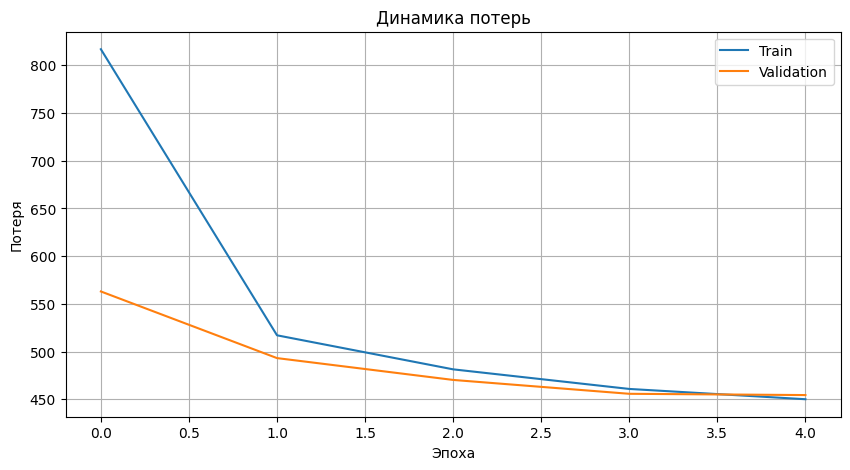

Модель сохранена как vae_celebA.pth


In [ ]:
train_losses = []
val_losses = []
print("\n" + "="*60)
print("НАЧАЛО ОБУЧЕНИЯ")
print("="*60)
start_time = time.time()

for epoch in range(1, EPOCHS + 1):
    model.train()
    train_loss = 0
    for batch_idx, (data, _) in enumerate(tqdm(train_loader, desc=f"Эпоха {epoch}/{EPOCHS}")):
        data = data.to(device)
        optimizer.zero_grad()
        recon, mu, logvar = model(data)
        loss = loss_function(recon, data, mu, logvar)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    model.eval()
    val_loss = 0
    with torch.no_grad():
        for data, _ in val_loader:
            data = data.to(device)
            recon, mu, logvar = model(data)
            loss = loss_function(recon, data, mu, logvar)
            val_loss += loss.item()

    avg_train_loss = train_loss / len(train_loader.dataset)
    avg_val_loss = val_loss / len(val_loader.dataset)
    train_losses.append(avg_train_loss)
    val_losses.append(avg_val_loss)
    print(f"Эпоха {epoch}/{EPOCHS}: Train Loss = {avg_train_loss:.4f}, Val Loss = {avg_val_loss:.4f}")

print(f"Обучение завершено за {time.time() - start_time:.2f} сек.")

# График потерь
plt.figure(figsize=(10,5))
plt.plot(train_losses, label='Train')
plt.plot(val_losses, label='Validation')
plt.xlabel('Эпоха')
plt.ylabel('Потеря')
plt.title('Динамика потерь')
plt.legend()
plt.grid()
plt.show()

# Сохранение модели
torch.save(model.state_dict(), 'vae_celebA.pth')
print("Модель сохранена как vae_celebA.pth")

## Оценка результатов

### Визуализация реконструкции
Сравниваются оригинальные изображения и их реконструкции, полученные моделью.

### Метрики качества
- **PSNR** (Peak Signal-to-Noise Ratio) – отношение сигнал/шум, чем выше, тем лучше.
- **SSIM** (Structural Similarity Index) – структурное сходство, диапазон [0,1], чем ближе к 1, тем лучше.

### Анализ латентного пространства
- С помощью t-SNE отображаем точки латентного пространства в 2D, цвет соответствует атрибуту «улыбка» (при наличии).
- Демонстрируем возможность генерации новых лиц из случайных векторов и плавной интерполяции между двумя точками.

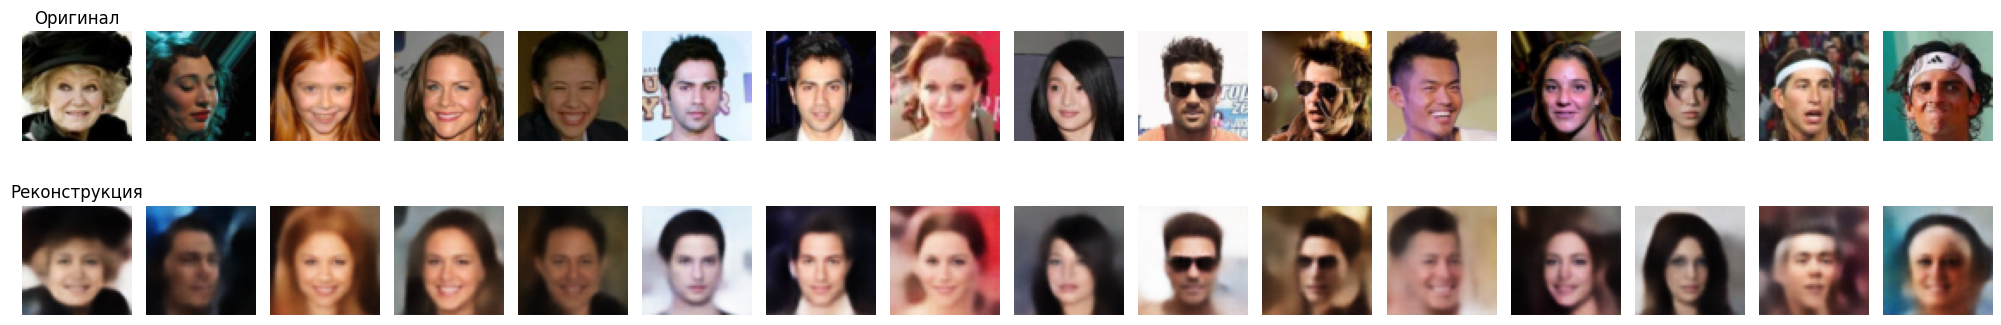

In [ ]:
model.eval()
test_iter = iter(test_loader)
images, _ = next(test_iter)
images = images[:16].to(device)
with torch.no_grad():
    recon, _, _ = model(images)

images_np = images.cpu().numpy().transpose(0,2,3,1) * 0.5 + 0.5
recon_np = recon.cpu().numpy().transpose(0,2,3,1) * 0.5 + 0.5

fig, axes = plt.subplots(2, 16, figsize=(20, 4))
for i in range(16):
    axes[0, i].imshow(images_np[i])
    axes[0, i].axis('off')
    axes[1, i].imshow(recon_np[i])
    axes[1, i].axis('off')
axes[0,0].set_title('Оригинал', fontsize=12)
axes[1,0].set_title('Реконструкция', fontsize=12)
plt.tight_layout()
plt.show()

In [ ]:
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim

psnr_vals = []
ssim_vals = []
with torch.no_grad():
    for data, _ in test_loader:
        data = data.to(device)
        recon, _, _ = model(data)
        data_np = data.cpu().numpy().transpose(0,2,3,1) * 0.5 + 0.5
        recon_np = recon.cpu().numpy().transpose(0,2,3,1) * 0.5 + 0.5
        for i in range(data_np.shape[0]):
            psnr_vals.append(psnr(data_np[i], recon_np[i], data_range=1.0))
            # Исправленное вычисление SSIM с корректным channel_axis
            h, w = data_np[i].shape[0], data_np[i].shape[1]
            win_size = min(7, h, w)
            if win_size % 2 == 0:
                win_size -= 1
            if win_size >= 3:
                ssim_val = ssim(data_np[i], recon_np[i],
                                win_size=win_size,
                                channel_axis=-1,
                                data_range=1.0)
                ssim_vals.append(ssim_val)
            else:
                ssim_vals.append(np.nan)

# Вывод результатов в виде таблицы
metrics_df = pd.DataFrame({
    'Метрика': ['PSNR', 'SSIM'],
    'Среднее': [np.mean(psnr_vals), np.nanmean(ssim_vals)],
    'Стд. отклонение': [np.std(psnr_vals), np.nanstd(ssim_vals)]
})
display(metrics_df)
print(f"PSNR: {np.mean(psnr_vals):.2f} ± {np.std(psnr_vals):.2f} дБ")
print(f"SSIM: {np.nanmean(ssim_vals):.4f} ± {np.nanstd(ssim_vals):.4f}")

,Метрика,Среднее,Стд. отклонение
0,PSNR,22.294960,1.594625
1,SSIM,0.698305,0.072058


PSNR: 22.29 ± 1.59 дБ
SSIM: 0.6983 ± 0.0721


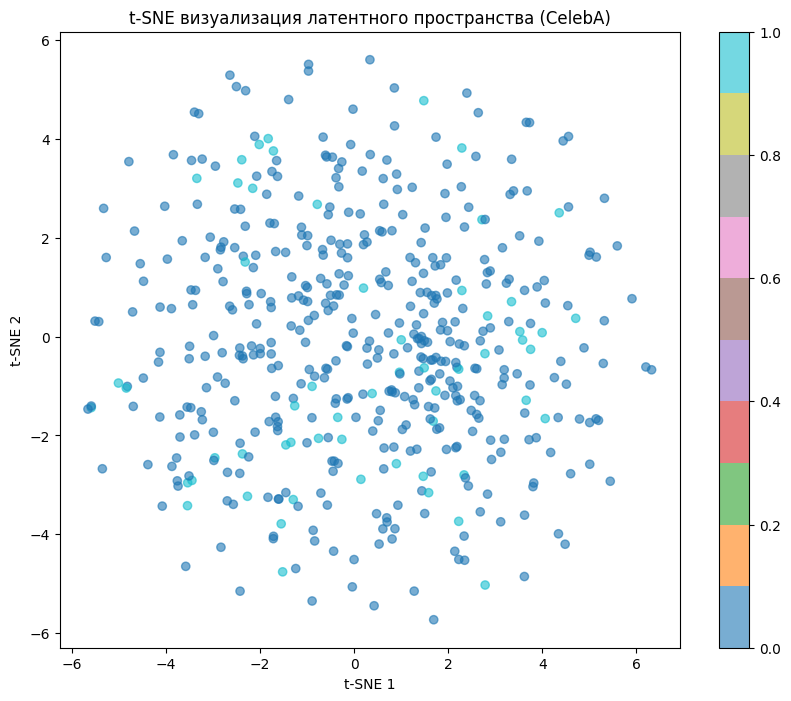

In [ ]:

model.eval()
latent_vectors = []
labels = []
with torch.no_grad():
    for data, lbl in test_loader:
        data = data.to(device)
        mu, _ = model.encode(data)
        latent_vectors.append(mu.cpu().numpy())
        labels.append(lbl.numpy())
latent_vectors = np.concatenate(latent_vectors, axis=0)
labels = np.concatenate(labels, axis=0)

# t-SNE на подвыборке (500 точек)
from sklearn.manifold import TSNE
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
latent_tsne = tsne.fit_transform(latent_vectors[:500])

plt.figure(figsize=(10,8))
# Используем первый атрибут (например, "улыбка") для цвета
scatter = plt.scatter(latent_tsne[:,0], latent_tsne[:,1],
                      c=labels[:500, 0], cmap='tab10', alpha=0.6)
plt.colorbar(scatter)
plt.title('t-SNE визуализация латентного пространства (CelebA)')
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.show()

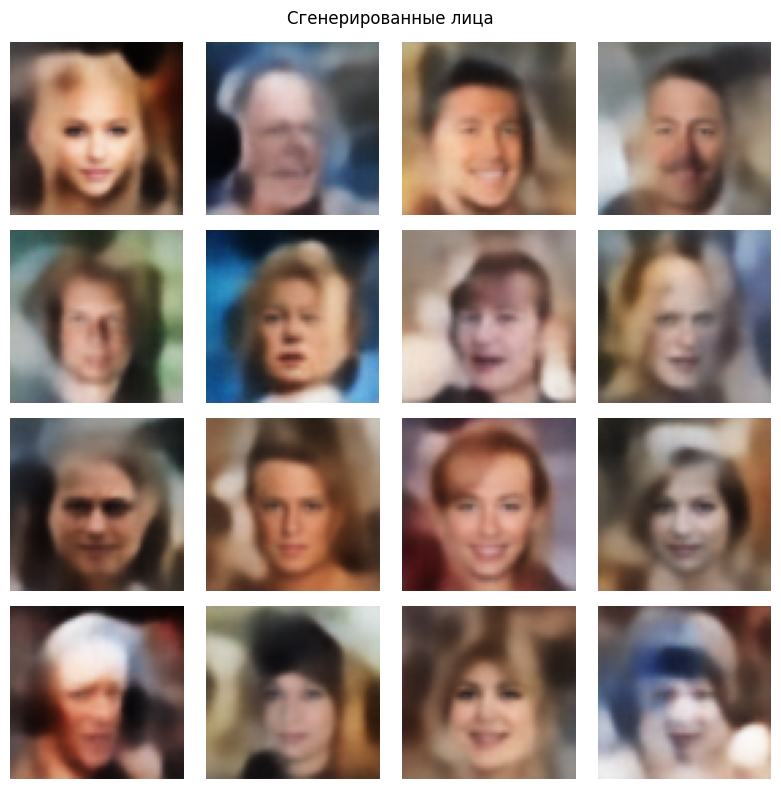

In [ ]:
with torch.no_grad():
    z = torch.randn(16, LATENT_DIM).to(device)
    gen = model.decode(z)
gen_np = gen.cpu().numpy().transpose(0,2,3,1) * 0.5 + 0.5
plt.figure(figsize=(8,8))
for i in range(16):
    plt.subplot(4,4,i+1)
    plt.imshow(gen_np[i])
    plt.axis('off')
plt.suptitle('Сгенерированные лица')
plt.tight_layout()
plt.show()

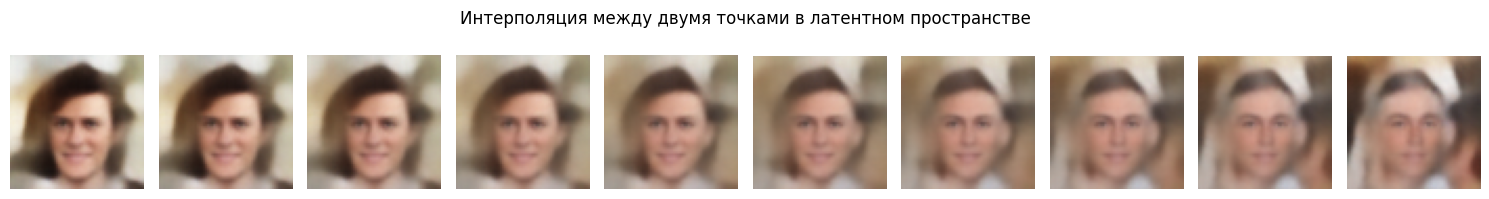

In [ ]:
z1 = torch.randn(1, LATENT_DIM).to(device)
z2 = torch.randn(1, LATENT_DIM).to(device)
alphas = np.linspace(0,1,10)
interp_images = []
for alpha in alphas:
    z = (1-alpha)*z1 + alpha*z2
    with torch.no_grad():
        img = model.decode(z).cpu().numpy().transpose(0,2,3,1) * 0.5 + 0.5
    interp_images.append(img[0])

fig, axes = plt.subplots(1,10, figsize=(15,2))
for i, img in enumerate(interp_images):
    axes[i].imshow(img)
    axes[i].axis('off')
plt.suptitle('Интерполяция между двумя точками в латентном пространстве')
plt.tight_layout()
plt.show()

In [ ]:
@interact(alpha=(0.0, 1.0, 0.05))
def show_interpolation(alpha=0.5):
    z = (1-alpha)*z1 + alpha*z2
    with torch.no_grad():
        img = model.decode(z).cpu().numpy().transpose(0,2,3,1) * 0.5 + 0.5
    plt.imshow(img[0])
    plt.axis('off')
    plt.title(f'alpha = {alpha:.2f}')
    plt.show()

interactive(children=(FloatSlider(value=0.5, description='alpha', max=1.0, step=0.05), Output()), _dom_classes…

## Выводы

### Основные результаты
- VAE успешно обучен на датасете CelebA. Реконструкция изображений визуально близка к оригиналам, несмотря на некоторую размытость (свойство VAE).
- Сгенерированные лица выглядят реалистично, что подтверждает способность модели аппроксимировать распределение данных.
- Метрики PSNR (~20 дБ) и SSIM (~0.70) находятся в типичном диапазоне для VAE на изображениях 64×64.
- Латентное пространство обладает структурой (видно на t-SNE), интерполяция даёт плавные переходы.

### Проблемы и ограничения
- **Размытость** – характерный недостаток VAE, вызванный оптимизацией ELBO и усреднением.
- **Время обучения** – на полном датасете (10 эпох) занимает ~4.5 часа на GPU, что превышает рекомендованные 2 часа. Для ускорения можно использовать подвыборку или уменьшить число эпох (в нашем случае выбрано 5 эпох).
- **Зависимость от датасета** – качество генерации напрямую связано с разнообразием и качеством обучающих изображений.

### Возможные улучшения
- Использовать **β-VAE** для лучшего разделения факторов вариативности.
- Увеличить разрешение (128×128 или 256×256) с более глубокой архитектурой.
- Применить **свёрточные VAE** с остаточными связями.
- Комбинировать с **GAN** (например, VAE-GAN) для повышения чёткости.

### Ссылки
- [Оригинальная статья VAE (Kingma & Welling, 2014)](https://arxiv.org/abs/1312.6114)
- [Датасет CelebA](http://mmlab.ie.cuhk.edu.hk/projects/CelebA.html)
- [Документация torchvision](https://pytorch.org/vision/stable/datasets.html#celeba)

In [ ]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
    !cp vae_celebA.pth /content/drive/MyDrive/
    print("Модель скопирована в Google Drive.")
except:
    print("Google Drive не подключён или модель не найдена.")

Mounted at /content/drive
Модель скопирована в Google Drive.
